# Classification Primer — Guided Practice

In the regression primer, you predicted a numerical house price. Here the target
is a **category**: can the words in a baby-product review help us predict whether
its star rating is positive or negative?

By the end, you should be able to:

- prepare text and create a clearly defined classification target;
- turn reviews into word-count features without learning from held-out data;
- construct, fit, and interpret a logistic-regression classifier;
- distinguish predicted labels from estimated probabilities;
- compare two vocabularies with a simple baseline and inspect their errors;
- choose an approach using validation data, then assess it once on a test set.



## How to work through this notebook

Complete Exercises 1–5 in order. Worked examples introduce new techniques on
tiny inputs. In **Your turn**, write complete blocks of code: prepare tables,
create and fit models, predict, organise results, and draw plots. The cells
contain comments rather than lines with single blanks.

Required object names are stated because later cells reuse them. You choose
intermediate names and how to organise your implementation. Try each task
before opening its optional hint. Written explanations are part of the work.

Run a checkpoint after completing the preceding task. An unfinished checkpoint
deliberately stops with a message. Once the core work is complete, restart the
kernel and run all cells in order. Extensions are optional.

We use **all eligible reviews**, with no fixed-size sample. Leave the test
reviews aside until Exercise 5. Keep the supplied split and model settings fixed
so the comparison answers a clear question.


## Setup — reviews and a proxy for sentiment

Keep **amazon_baby.csv beside this notebook**. In Colab, upload the CSV into
the session's files. You need pandas, numpy, matplotlib, and scikit-learn.
The CSV is supplied with this assignment; no online service or account is needed.

A row contains a product name, review text, and rating. We define **1–2 stars
as negative (−1)** and **4–5 stars as positive (+1)**. We leave out 3-star
reviews to keep this first task binary. This does not mean all 3-star texts
express neutral feelings. Ratings are a useful **proxy label**, not a direct
measurement of every sentence's sentiment.

Use review text as input. The rating creates the target and must not also be
an input feature. Product names are available for inspection, not modelling.

Counting words and fitting on the full dataset can take a few minutes on a laptop. Keep the large word-count matrices sparse.


In [35]:
from pathlib import Path
from time import perf_counter
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, recall_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.pipeline import make_pipeline
from sklearn.base import clone

possible_paths = [Path("amazon_baby.csv"), Path("Primer Assignments") / "amazon_baby.csv"]
data_path = next((path for path in possible_paths if path.is_file()), None)
if data_path is None:
    raise FileNotFoundError("Put amazon_baby.csv beside this notebook, then run this cell again.")
reviews = pd.read_csv(data_path)
print("Source records:", len(reviews))
display(reviews.head())


Source records: 183531


,name,review,rating
0,Planetwise Flannel Wipes,"These flannel wipes are OK, but in my opinion ...",3
1,Planetwise Wipe Pouch,it came early and was not disappointed. i love...,5
2,Annas Dream Full Quilt with 2 Shams,Very soft and comfortable and warmer than it l...,5
3,Stop Pacifier Sucking without tears with Thumb...,This is a product well worth the purchase. I ...,5
4,Stop Pacifier Sucking without tears with Thumb...,All of my kids have cried non-stop when I trie...,5


## Exercise 1 — Prepare the target and inspect the balance

**Your turn — audit the input.** Display the number of missing values in
each column and a table counting ratings from 1 to 5. Then find two nonmissing
example reviews with different ratings and display their text and rating.
Explain whether their labels seem reasonable; a mixed review is also useful.

Keep reviews unchanged so you can compare the prepared data with the source.


In [36]:
# Your code: inspect missing values, count ratings, and show two contrasting examples.
# Count missing values and ratings from 1 to 5
display(reviews.isna().sum().to_frame("missing_values"))

rating_counts = reviews["rating"].value_counts().reindex(range(1, 6), fill_value=0)
display(rating_counts.rename_axis("rating").to_frame("count"))

# Show one short review for each of the two ratings
text_length = reviews["review"].str.len()
for rating in [1, 5]:
    example = reviews.loc[
        (reviews["rating"] == rating) & text_length.between(20, 100),
        "review",
    ].iloc[0]
    print(f"\nRating: {rating}/5")
    print(example)

,missing_values
name,318
review,829
rating,0


,count
rating,
1,15183
2,11310
3,16779
4,33205
5,107054



Rating: 1/5
These do not stick to the wall. They start to peel as soon as you stick them to the wall.

Rating: 5/5
My son likes brushing elmo's teeth. Almost too nice of a book to let the kids play with haha :)


**Worked example — a small text-cleaning function.** This deliberately simple
function deletes ASCII punctuation. It takes a string, so replace missing
values **before** calling it. Series.apply applies a function to each element.

Deleting punctuation has costs: "don't" becomes "dont", and "easy-to-use"
becomes "easytouse". We keep this rule fixed to study its limitations.
Cleaning text is not the same as understanding it.


In [37]:
def remove_punctuation(text):
    translator = str.maketrans("", "", string.punctuation)
    return text.translate(translator)

tiny_texts = pd.Series(["Easy-to-use! I don't regret it.", None])
tiny_cleaned = tiny_texts.fillna("").apply(remove_punctuation).str.lower().str.strip()
display(pd.DataFrame({"Original": tiny_texts, "Cleaned": tiny_cleaned}))


,Original,Cleaned
0,Easy-to-use! I don't regret it.,easytouse i dont regret it
1,NaN,


**Your turn — implement the full preparation.** Create a copy of reviews named
**prepared_reviews**. Preserve the original review and rating columns.

1. Create **review_clean** by filling missing review text with an empty string,
   applying remove_punctuation, converting to lower case, and stripping
   whitespace from the ends.
2. Keep only ratings 1, 2, 4, and 5. Remove rows whose cleaned review is empty:
   there is no text to learn from. Do not discard a review because its product
   name is missing.
3. Create **sentiment**, equal to −1 for ratings 1–2 and +1 for ratings 4–5.
4. Print how many records remain. Construct **class_counts**, a Series with
   counts indexed by −1 and +1. Display counts and percentages, then draw a
   labelled bar chart of the two classes.

Do not take a random sample or balance the classes by deleting positive reviews.
The imbalance is part of the prediction problem.

<details><summary>Optional preparation hints</summary>

Start from reviews.copy(). Series.isin([1, 2, 4, 5]) makes a selection mask;
select rows with .loc[mask].copy(). np.where(condition, value_if_true,
value_if_false) can create the two labels. value_counts().sort_index()
counts labels in order. A Series can be plotted using .plot.bar(ax=ax).

</details>


Reviews remaining: 165,974


,count,percentage
sentiment,,
-1,26393,15.9
1,139581,84.1


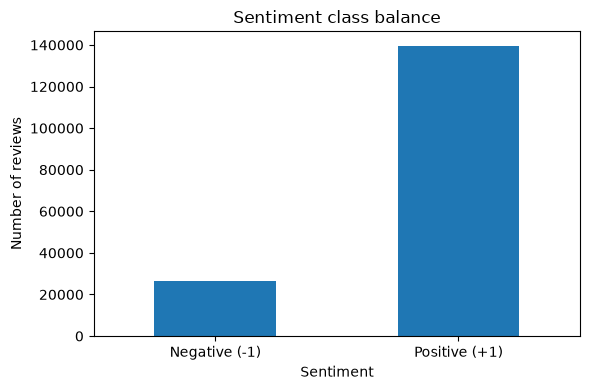

In [38]:
# Your code: prepare the complete eligible dataset, create class_counts, and plot the class balance.

# Clean the review text in a copy of the original data
prepared_reviews = reviews.copy()
prepared_reviews["review_clean"] = (
    prepared_reviews["review"]
    .fillna("")
    .apply(remove_punctuation)
    .str.lower()
    .str.strip()
)

# Keep eligible ratings and reviews with text after cleaning
valid_rating = prepared_reviews["rating"].isin([1, 2, 4, 5])
has_text = prepared_reviews["review_clean"].ne("")
prepared_reviews = prepared_reviews.loc[valid_rating & has_text].copy()

# Assign sentiment labels and summarize the class balance
prepared_reviews["sentiment"] = np.where(prepared_reviews["rating"].ge(4), 1, -1)
class_counts = prepared_reviews["sentiment"].value_counts().sort_index()
class_summary = class_counts.to_frame("count")
class_summary["percentage"] = (100 * class_counts / class_counts.sum()).round(2)

print(f"Reviews remaining: {len(prepared_reviews):,}")
display(class_summary)

# Plot the number of reviews in each class
fig, ax = plt.subplots(figsize=(6, 4))
class_counts.plot.bar(ax=ax, rot=0)
ax.set_xticklabels(["Negative (-1)", "Positive (+1)"])
ax.set_xlabel("Sentiment")
ax.set_ylabel("Number of reviews")
ax.set_title("Sentiment class balance")
plt.tight_layout()
plt.show()


In [39]:
assert "prepared_reviews" in globals() and "class_counts" in globals(), "Prepare the reviews and count the two classes first."
expected_clean = reviews["review"].fillna("").apply(remove_punctuation).str.lower().str.strip()
expected_index = reviews.index[reviews["rating"].isin([1, 2, 4, 5]) & expected_clean.ne("")]
assert prepared_reviews.index.equals(expected_index), "Keep every eligible review, in its original order, with no sample cap."
assert prepared_reviews["review_clean"].equals(expected_clean.loc[expected_index]), "Check missing text, punctuation, case, and whitespace."
expected_labels = np.where(prepared_reviews["rating"].ge(4), 1, -1)
assert np.array_equal(prepared_reviews["sentiment"], expected_labels), "Check the rating-to-sentiment rule."
assert class_counts.sort_index().equals(prepared_reviews["sentiment"].value_counts().sort_index()), "Count the prepared labels."
print("Checkpoint passed: the full eligible dataset and its two labels are ready.")


Checkpoint passed: the full eligible dataset and its two labels are ready.


**Explain:** Which class is more common? Roughly what accuracy would a rule
predicting that class for every review achieve? Would that rule identify
any negative reviews? Explain why a high-looking accuracy can be misleading.
Also explain why rating must not be used as an input.


_Your answer:_
Positive reviews are more common. Predicting +1 every time would give about 84% accuracy while missing every negative review. That score mostly reflects how common positive reviews are.

The star rating is used to create the sentiment label. Giving the rating to the model would let it recover the answer directly instead of learning from the review text.


## Exercise 2 — From text to numerical features

**Worked example — bag of words.** CountVectorizer learns a vocabulary from
training text and counts each word. Each row is a review, each column a token
(a word-like unit), and each entry its count. The default lowercases text and
ignores single-character tokens. Repeated words increase their counts.

The result is a **sparse matrix**: it stores nonzero counts efficiently. We turn
only this tiny example into a dense table. Keep the real review matrices sparse;
do not call .toarray() or .todense() on the full dataset.


In [40]:
toy_reviews = [
    "we love this easy product",
    "great product we love it",
    "we hate this broken product",
    "awful product we hate it",
    "we love love this",
    "we hate hate this",
]
toy_labels = np.array([1, 1, -1, -1, 1, -1])
toy_vectorizer = CountVectorizer()
X_toy = toy_vectorizer.fit_transform(toy_reviews)
toy_words = toy_vectorizer.get_feature_names_out()
display(pd.DataFrame(X_toy.toarray(), columns=toy_words, index=toy_reviews))

toy_new_reviews = ["we love bananas", "bananas"]
X_toy_new = toy_vectorizer.transform(toy_new_reviews)
display(pd.DataFrame(X_toy_new.toarray(), columns=toy_words, index=toy_new_reviews))


,awful,broken,easy,great,hate,it,love,product,this,we
we love this easy product,0,0,1,0,0,0,1,1,1,1
great product we love it,0,0,0,1,0,1,1,1,0,1
we hate this broken product,0,1,0,0,1,0,0,1,1,1
awful product we hate it,1,0,0,0,1,1,0,1,0,1
we love love this,0,0,0,0,0,0,2,0,1,1
we hate hate this,0,0,0,0,2,0,0,0,1,1


,awful,broken,easy,great,hate,it,love,product,this,we
we love bananas,0,0,0,0,0,0,1,0,0,1
bananas,0,0,0,0,0,0,0,0,0,0


**Read the tables:** Why is bananas absent from the columns? What happened to
the second new review? Would "we love this product" and "this product we love"
have different count vectors? State one meaning the representation loses.


_Your answer:_

“Bananas” is missing from the columns because it never appeared in the training reviews. The second new review contains only “bananas,” so its vector is all zeros.

“We love this product” and “this product we love” have the same vector because each word appears once in both. Word order is lost, so the representation cannot tell “dog bites man” from “man bites dog.”


### Three groups, with matching review texts kept together

We reuse the regression workflow: approximately **60% training**, **20%
validation**, and **20% test**. All eligible records are retained.

Some review texts repeat. A random row split could put a copy of a review in
both training and evaluation. The supplied GroupShuffleSplit assigns groups
defined by the same cleaned text (ignoring repeated whitespace) together.
Its test_size refers to groups, so row percentages are approximate. This new
splitting method is supplied; you are not expected to implement it.

The split does **not** separate products, authors, near-duplicate texts, or time
periods. It assesses other reviews in a similar dataset, not performance on
entirely new products or future reviews. Missing author/time information also
limits what we can check.

We inspect class balance in training and validation only. Test labels are not
used to compare models or choose settings.


In [41]:
prepared_reviews["review_group"] = prepared_reviews["review_clean"].str.split().str.join(" ")
first_split = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=44)
development_positions, test_positions = next(
    first_split.split(prepared_reviews, groups=prepared_reviews["review_group"])
)
development_data = prepared_reviews.iloc[development_positions].copy()
test_data = prepared_reviews.iloc[test_positions].copy()

second_split = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=44)
train_positions, validation_positions = next(
    second_split.split(development_data, groups=development_data["review_group"])
)
train_data = development_data.iloc[train_positions].copy()
validation_data = development_data.iloc[validation_positions].copy()
y_train = train_data["sentiment"]
y_validation = validation_data["sentiment"]

print("Training / validation / reserved test rows:", len(train_data), len(validation_data), len(test_data))
print("Repeated text records beyond the first:", prepared_reviews["review_group"].duplicated().sum())
display(pd.DataFrame({
    "Training share": y_train.value_counts(normalize=True),
    "Validation share": y_validation.value_counts(normalize=True),
}).sort_index())

assert len(train_data) + len(validation_data) + len(test_data) == len(prepared_reviews)
for left, right in [(train_data, validation_data), (train_data, test_data), (validation_data, test_data)]:
    assert set(left["review_group"]).isdisjoint(right["review_group"])


Training / validation / reserved test rows: 99602 33178 33194
Repeated text records beyond the first: 163


,Training share,Validation share
sentiment,,
-1,0.160157,0.157574
1,0.839843,0.842426


**Your turn — build the real feature matrices.** Create a new CountVectorizer
named **full_vectorizer**, using its default settings. Learn its vocabulary
and create **X_train** from train_data["review_clean"]. Create
**X_validation** using the same fitted vocabulary and validation review text.

Pass a **one-dimensional Series of strings**, using single brackets to select the text column. The vectorizer creates the two-dimensional feature matrix for the classifier.

Print both matrix shapes, the vocabulary size, and the number of stored
nonzero entries in X_train (its .nnz attribute). Explain what the two dimensions
mean. Use every training and validation review and keep both matrices sparse.
Here "full" means the complete vocabulary learned by this tokenizer from
training reviews, rather than the 20-word vocabulary used later.

<details><summary>Optional API hint</summary>

fit_transform learns the vocabulary and produces counts. transform only
produces counts using an already learned vocabulary. The toy example shows
both operations. get_feature_names_out() returns the learned column names.

</details>


In [42]:
# Your code: create the vectorizer, learn training counts, transform validation text, and report their dimensions.

# Learning the vocabulary and count tokens in the training reviews
full_vectorizer = CountVectorizer()
X_train = full_vectorizer.fit_transform(train_data["review_clean"])

# Count tokens in the validation reviews using the same vocabulary
X_validation = full_vectorizer.transform(validation_data["review_clean"])

print("Training matrix shape:", X_train.shape)
print("Validation matrix shape:", X_validation.shape)
print(f"Vocabulary size: {len(full_vectorizer.get_feature_names_out()):,}")
print(f"Nonzero entries in X_train: {X_train.nnz:,}")

Training matrix shape: (99602, 100264)
Validation matrix shape: (33178, 100264)
Vocabulary size: 100,264
Nonzero entries in X_train: 5,308,053


In [43]:
assert all(name in globals() for name in ["full_vectorizer", "X_train", "X_validation"]), "Create the vectorizer and both sparse matrices first."
assert X_train.shape[0] == len(train_data) and X_validation.shape[0] == len(validation_data), "Use the assigned rows."
assert X_train.shape[1] == X_validation.shape[1] == len(full_vectorizer.get_feature_names_out()), "Both groups must use the same vocabulary."
assert full_vectorizer.get_params()["vocabulary"] is None, "Learn the first model's vocabulary from training text."
assert (X_train != full_vectorizer.transform(train_data["review_clean"])).nnz == 0, "Check the training matrix and its row order."
assert (X_validation != full_vectorizer.transform(validation_data["review_clean"])).nnz == 0, "Transform validation text using the fitted training vectorizer."
print("Checkpoint passed: consistent word-count columns for training and validation.")


Checkpoint passed: consistent word-count columns for training and validation.


**Explain:** What does each dimension of X_train represent? Why must we avoid
fitting a new vectorizer on validation text? Why would fitting on the entire
dataset before splitting also be a problem?

_Your answer:_

Each row represents one review, and each column represents one token in the training vocabulary. A cell shows how many times that token appears in the review. There are 99,602 training rows and 33,178 validation rows. Both matrices have the same columns because they use the same fitted vectorizer.

Fitting a separate vectorizer on validation could change which token each column represents. Fitting on the entire dataset before the split would also let validation and test reviews influence the vocabulary.


## Exercise 3 — Learn a classifier and a baseline

**Worked example — logistic regression.** Despite its name, LogisticRegression
is a classification model. It combines word counts using learned coefficients
and converts the resulting score into an estimated probability between 0 and 1.
No logistic-function algebra is required here.

- .fit(counts, labels) learns from labelled training examples.
- .predict(counts) returns a label.
- .predict_proba(counts) returns one column per label, in .classes_ order.

For this binary model with classes [−1, +1], a positive coefficient pushes
the score towards +1, holding other counts fixed. A coefficient is not itself
a probability. We fix solver="liblinear", C=1.0, max_iter=1000, and
random_state=44 in this primer. The solver is the fitting routine; C controls
coefficient regularisation. Tuning these settings is outside the core work.


In [44]:
toy_model = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000, random_state=44)
toy_model.fit(X_toy, toy_labels)
positive_column_toy = list(toy_model.classes_).index(1)
toy_probabilities = toy_model.predict_proba(X_toy_new)[:, positive_column_toy]
print("Probability columns correspond to:", toy_model.classes_)
display(pd.DataFrame({
    "Text": toy_new_reviews,
    "Predicted label": toy_model.predict(X_toy_new),
    "Estimated P(+1)": toy_probabilities,
}))


Probability columns correspond to: [-1  1]


,Text,Predicted label,Estimated P(+1)
0,we love bananas,1,0.695836
1,bananas,1,0.500000


**Your turn — fit and apply the full-vocabulary model.** Create **full_model**
with the fixed LogisticRegression settings above. Fit it on X_train and y_train.
Measure just the .fit call with perf_counter and save **full_fit_seconds**.

Predict validation labels as **full_validation_predictions**. Separately time
just that .predict call as **full_predict_seconds**. Then obtain **full_p_positive**,
a one-dimensional array containing each validation review's estimated probability
of +1. Find the correct probability column from full_model.classes_.

Display labels and positive probabilities for the first five validation rows,
together with their ratings. Keep the row order consistent.

<details><summary>Optional timing and probability hints</summary>

Save start = perf_counter() immediately before the operation and subtract it
from perf_counter() immediately after. The toy example shows how to find the
probability column. An array slice [:5] selects the first five entries.

</details>


In [45]:
# Your code: construct full_model, fit and time it, predict labels and probabilities, and display a small result table.
full_model = LogisticRegression(
    solver="liblinear", C=1.0, max_iter=1000, random_state=44
)

# Time model fitting on the training data
start = perf_counter()
full_model.fit(X_train, y_train)
full_fit_seconds = perf_counter() - start

# Time label prediction on the validation data
start = perf_counter()
full_validation_predictions = full_model.predict(X_validation)
full_predict_seconds = perf_counter() - start

# Select the probability column for the positive class
positive_column = list(full_model.classes_).index(1)
full_p_positive = full_model.predict_proba(X_validation)[:, positive_column]

# Show the first five validation reviews in their original order
preview = validation_data[["rating"]].head(5).copy()
preview["predicted_sentiment"] = full_validation_predictions[:5]
preview["p_positive"] = full_p_positive[:5]

print(f"Fit time: {full_fit_seconds:.3f} s")
print(f"Prediction time: {full_predict_seconds:.3f} s")
display(preview)

Fit time: 28.535 s
Prediction time: 0.008 s


,rating,predicted_sentiment,p_positive
2,5,1,0.994713
4,5,1,0.999662
6,4,1,0.903485
15,4,1,0.999823
18,4,1,0.993975


In [46]:
required = ["full_model", "full_validation_predictions", "full_p_positive", "full_fit_seconds", "full_predict_seconds"]
assert all(name in globals() for name in required), "Complete model fitting, timed prediction, and positive-class probabilities."
assert np.array_equal(full_model.classes_, [-1, 1]), "Fit using the requested sentiment labels."
assert np.array_equal(full_validation_predictions, full_model.predict(X_validation)), "Predict the validation reviews in their original order."
positive_column = list(full_model.classes_).index(1)
assert np.asarray(full_p_positive).shape == (len(validation_data),), "Keep one positive-class probability per review."
assert np.allclose(full_p_positive, full_model.predict_proba(X_validation)[:, positive_column]), "Check the probability column."
assert full_fit_seconds >= 0 and full_predict_seconds >= 0, "Store elapsed durations in seconds."
print("Checkpoint passed: labels and estimated positive probabilities are aligned.")


Checkpoint passed: labels and estimated positive probabilities are aligned.


**Worked example — the majority-class baseline.** DummyClassifier with
strategy="most_frequent" learns only the most common training label and predicts
it for everyone. Its API matches the other classifiers.

Accuracy is the proportion of correct labels: correct predictions / all
predictions. It is not an average of the model's predicted probabilities.


In [47]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_validation_predictions = baseline.predict(X_validation)
baseline_validation_accuracy = accuracy_score(y_validation, baseline_validation_predictions)
print("Baseline's predicted class:", baseline_validation_predictions[0])
print(f"Baseline validation accuracy: {baseline_validation_accuracy:.2%}")


Baseline's predicted class: 1
Baseline validation accuracy: 84.24%


**Your turn — calculate and organise performance.** Predict training labels
with full_model and calculate **full_training_accuracy**. Calculate
**full_validation_accuracy** from the validation predictions already obtained.

Build and display **initial_comparison**, a two-row DataFrame with the baseline
and full-vocabulary model, showing training and validation accuracy for each.
Also print the validation improvement over the baseline in **percentage points**.
For example, 0.90 − 0.85 = 0.05 is an improvement of 5 percentage points.


In [48]:
# Your code: calculate both models' training/validation accuracy, build initial_comparison, and report the improvement.

# Calculate training accuracy for both models
baseline_training_accuracy = accuracy_score(y_train, baseline.predict(X_train))
full_training_accuracy = accuracy_score(y_train, full_model.predict(X_train))

# Reuse the predictions already made on the validation set
full_validation_accuracy = accuracy_score(y_validation, full_validation_predictions)

initial_comparison = pd.DataFrame(
    {
        "Training accuracy": [baseline_training_accuracy, full_training_accuracy],
        "Validation accuracy": [baseline_validation_accuracy, full_validation_accuracy],
    },
    index=["Baseline", "Full vocabulary"],
)
display(initial_comparison)

improvement_pp = 100 * (full_validation_accuracy - baseline_validation_accuracy)
print(f"Validation improvement: {improvement_pp:.2f} percentage points")

,Training accuracy,Validation accuracy
Baseline,0.839843,0.842426
Full vocabulary,0.973013,0.930134


Validation improvement: 8.77 percentage points


**Compare:** Does learning from words help compared with the baseline? Quote
validation values. Is training accuracy enough to assess that? What does a
probability of 0.95 mean, and does it guarantee that a review is positive?


_Your answer:_

Learning from words helped. The full-vocabulary model reached 93.01% validation accuracy, compared with 84.24% for the baseline, an improvement of 8.77 percentage points. Training accuracy only measures performance on reviews the model has already seen. A predicted probability of 0.95 means the model estimates a 95% chance that the review belongs to the positive class. It can still be wrong.


## Exercise 4 — Interpret words, probabilities, and mistakes

**Your turn — connect word names to coefficients.** Construct **word_weights**,
a DataFrame containing columns **word** and **coefficient**, with one row per
token. Pair full_vectorizer.get_feature_names_out() with full_model.coef_[0]
in their existing order. Display the 10 largest and 10 smallest coefficients.

Draw two horizontal bar charts, one for each group, with readable word labels,
titles, and a coefficient axis. Students in the same course may obtain
unintuitive words; interpret the fitted association rather than invent a
linguistic rule. Large coefficients on rare tokens deserve caution.

<details><summary>Optional table and plotting hints</summary>

DataFrame.nlargest(10, "coefficient") and .nsmallest(10, "coefficient")
select extreme values. ax.barh(words, coefficients) makes horizontal bars.
fig, axes = plt.subplots(1, 2, ...) gives two axes for related charts.

</details>


,word,coefficient
75697,saves,2.243103
96255,warnings,2.045385
33226,excellent,2.018488
29745,downside,1.979629
10964,awesome,1.955466
79399,skeptical,1.938651
50999,lifesaver,1.923276
64984,perfect,1.898750
65041,perfectly,1.879363
87376,thankful,1.832079


,word,coefficient
99119,worthless,-2.707725
28825,dissapointed,-2.680257
28355,disappointing,-2.660886
99104,worst,-2.629839
77663,shame,-2.514789
67226,poor,-2.481524
22748,concept,-2.411203
92723,unacceptable,-2.375830
73733,returning,-2.359060
94366,useless,-2.354596


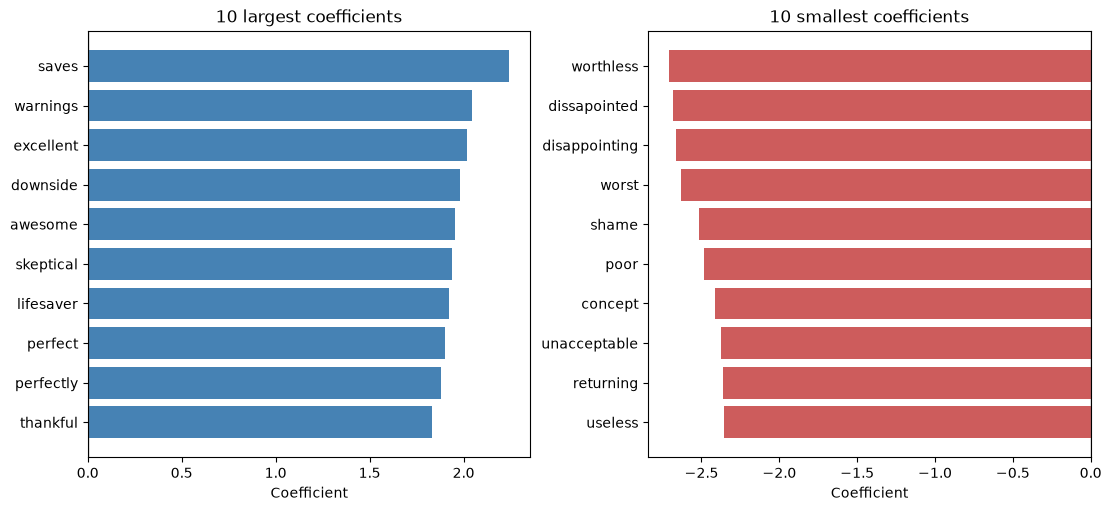

In [49]:
# Your code: build word_weights, show both extremes, and construct two labelled coefficient plots.

# Pair each token with its fitted coefficient
word_weights = pd.DataFrame({
    "word": full_vectorizer.get_feature_names_out(),
    "coefficient": full_model.coef_[0],
})

largest_weights = word_weights.nlargest(10, "coefficient")
smallest_weights = word_weights.nsmallest(10, "coefficient")

display(largest_weights)
display(smallest_weights)

# Plot the two groups of coefficients
fig, axes = plt.subplots(1, 2, figsize=(11, 5), layout="constrained")
for ax, weights, title, color in [
    (axes[0], largest_weights, "10 largest coefficients", "steelblue"),
    (axes[1], smallest_weights, "10 smallest coefficients", "indianred"),
]:
    ax.barh(weights["word"], weights["coefficient"], color=color)
    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlabel("Coefficient")
    ax.axvline(0, color="gray", linewidth=1)

plt.show()

**Your turn — rank estimated sentiment.** Make **validation_predictions_table**
by copying the name, review, rating, and sentiment columns of validation_data.
Add columns **predicted_sentiment**, **p_positive**, and **review_preview**.
The preview should contain the first 180 characters of the original review.
Attach prediction arrays positionally so they stay with the correct rows.

Display the five rows with the highest and five with the lowest p_positive,
showing ratings, labels, probabilities, and previews. Then display the first
three misclassified validation reviews in their existing order. Read their
**complete** text when explaining an error; a preview may hide the key sentence.

Highest and lowest probabilities mean the model's strongest estimated
sentiments, not reviews we have independently proved to be the most extreme.

<details><summary>Optional selection hints</summary>

Use .copy() before adding columns. .str.slice(0, 180) makes text previews.
A Boolean mask comparing sentiment and predicted_sentiment selects errors.
.head(3) selects the first three rows, with no cherry-picking.

</details>


In [50]:
# Your code: assemble the aligned prediction table, rank both probability extremes, and inspect three complete errors.

# Attach predictions to the validation rows in their original order
validation_predictions_table = validation_data[
    ["name", "review", "rating", "sentiment"]
].copy()
validation_predictions_table["predicted_sentiment"] = full_validation_predictions
validation_predictions_table["p_positive"] = full_p_positive
validation_predictions_table["review_preview"] = (
    validation_predictions_table["review"].str.slice(0, 180)
)

preview_columns = [
    "rating", "sentiment", "predicted_sentiment", "p_positive", "review_preview"
]

print("Highest estimated P(+1)")
display(validation_predictions_table.nlargest(5, "p_positive")[preview_columns])

print("Lowest estimated P(+1)")
display(validation_predictions_table.nsmallest(5, "p_positive")[preview_columns])

# Show the first three mistakes and print the complete review text
is_error = (
    validation_predictions_table["sentiment"]
    != validation_predictions_table["predicted_sentiment"]
)
first_errors = validation_predictions_table.loc[is_error].head(3)

print("First three misclassified reviews")
display(first_errors[preview_columns])

for row_index, review in first_errors["review"].items():
    print(f"\nRow {row_index}")
    print(review)


Highest estimated P(+1)


,rating,sentiment,predicted_sentiment,p_positive,review_preview
1798,4,1,1,1.0,I bought this product because of the great rev...
21557,5,1,1,1.0,"Ok, I read all the reviews already posted here..."
22586,4,1,1,1.0,I researched a few different seats to put in o...
41763,4,1,1,1.0,After considering several lightweight stroller...
52631,5,1,1,1.0,After seeing this in Parent's Magazine and rea...


Lowest estimated P(+1)


,rating,sentiment,predicted_sentiment,p_positive,review_preview
175191,1,-1,-1,1.476579e-22,I had to return this stroller for three reason...
133297,1,-1,-1,2.117480e-17,The first monitor broke within 1 month of use-...
120707,1,-1,-1,1.077622e-16,"The previous reviewers laud the ""piece of mind..."
68194,1,-1,-1,4.634066e-16,I'm sure that this product passed all the form...
7143,2,-1,-1,2.953173e-14,"I actually didnt buy this, someone else did, b..."


First three misclassified reviews


,rating,sentiment,predicted_sentiment,p_positive,review_preview
84,1,-1,1,0.673514,"The steel part is not strong at all, unlike th..."
242,1,-1,1,0.962099,My four month old started teething around two ...
278,1,-1,1,0.886070,I think the idea behind the sling is great but...



Row 84
The steel part is not strong at all, unlike the old diaper pins, which I still have.  Very hard to work it through a thicker fabric.  Would not recommend.

Row 242
My four month old started teething around two months, he has pretty impressive motor skills when it comes to using his hands but this teether is huge and you really have to apply quite a bit of pressure for it to vibrate. My other son who is two and also teething shows absolutely no intrest in this at all. Maybe in a couple more months....

Row 278
I think the idea behind the sling is great but it is not for every baby.  Everytime our son is put in this he crys or screams.  He is an easy going fellow but he hasn't liked being held to closely.  He wants his freedom and this doesn't give much freedom to a newborn.  Also, the &quot;training&quot; video is more of a promotional advertisement.  I had to go to the web site to get more information about how to use it.


**Interpret:** Give one positive-coefficient word and one negative-coefficient
word and explain their signs. Does a positive coefficient guarantee a positive
label whenever that word occurs? Choose one of the first three displayed errors,
identify its row, summarise its text, and suggest a plausible reason for the
error. Separate what you observed from what you hypothesise.


_Your answer:_

excellent has a positive coefficient, so it pushes the prediction toward +1. worthless has a negative coefficient and pushes it toward −1. The final label depends on the combined weights of the words in the review, so one positive word does not guarantee a positive prediction.

Observation: Row 278 gave the baby sling one star, but the model predicted +1 with an estimated probability of about 0.89. The reviewer liked the idea of the sling, but their baby cried whenever they used it, and they found the tutorial video too promotional.

Possible explanation: The model counts words separately. It may have picked up on “great,” which describes the idea, and “easy,” which describes the baby, without capturing what those words refer to.


### Accuracy can hide missed negative reviews

**Worked example — reading a confusion matrix.** Rows are actual labels;
columns are predicted labels. We explicitly order both as **[−1, +1]**:

| | Predicted −1 | Predicted +1 |
|---|---|---|
| Actual −1 | Correctly detected negative | Missed negative |
| Actual +1 | Positive flagged as negative | Correctly detected positive |

**Negative-class recall** asks: of all actually negative reviews, what share
did we detect? It is the first cell / the sum of the first row. Calling
recall_score(..., pos_label=-1) makes −1 the class of interest for that metric.
The dataset labels and probability-column order stay unchanged.


In [51]:
example_actual = np.array([-1, -1, -1, 1, 1, 1])
example_predicted = np.array([-1, 1, 1, -1, 1, 1])
example_matrix = confusion_matrix(example_actual, example_predicted, labels=[-1, 1])
display(pd.DataFrame(example_matrix, index=["Actual −1", "Actual +1"], columns=["Predicted −1", "Predicted +1"]))
print(f"Negative recall = 1/3 = {recall_score(example_actual, example_predicted, pos_label=-1):.1%}")


,Predicted −1,Predicted +1
Actual −1,1,2
Actual +1,1,2


Negative recall = 1/3 = 33.3%


**Your turn — assess the real mistakes.** Calculate **full_confusion** with
labels=[-1, 1]. Display a labelled matrix using ConfusionMatrixDisplay (or your
own labelled plot). Calculate **full_negative_recall** using pos_label=-1.
Calculate the baseline's negative recall too, and display both values.

Print how many negative reviews the full model missed and how many positive
reviews it incorrectly flagged as negative. Use the stated row/column order.

<details><summary>Optional plotting hint</summary>

ConfusionMatrixDisplay(confusion_matrix=matrix,
display_labels=["Negative (−1)", "Positive (+1)"]).plot(values_format="d")
displays counts. Keep axis labels and a title explaining which group is shown.

</details>


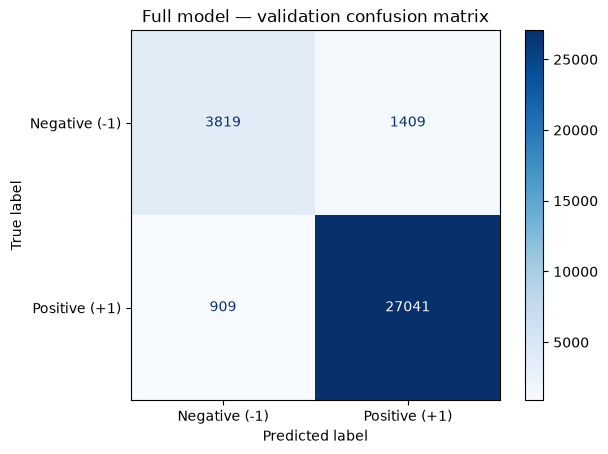

Full model negative recall: 73.05%
Baseline negative recall: 0.00%
Missed negative reviews: 1,409
Positive reviews flagged as negative: 909

Full model — validation classification report
               precision    recall  f1-score   support

Negative (-1)      0.808     0.730     0.767      5228
Positive (+1)      0.950     0.967     0.959     27950

     accuracy                          0.930     33178
    macro avg      0.879     0.849     0.863     33178
 weighted avg      0.928     0.930     0.929     33178


Baseline — validation classification report
               precision    recall  f1-score   support

Negative (-1)      0.000     0.000     0.000      5228
Positive (+1)      0.842     1.000     0.914     27950

     accuracy                          0.842     33178
    macro avg      0.421     0.500     0.457     33178
 weighted avg      0.710     0.842     0.770     33178



In [59]:
# Your code: calculate and plot full_confusion, compare negative recall, and count the two types of errors.

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
    recall_score,
)

# Build and plot the confusion matrix in negative, positive order
full_confusion = confusion_matrix(
    y_validation, full_validation_predictions, labels=[-1, 1]
)

matrix_display = ConfusionMatrixDisplay(
    confusion_matrix=full_confusion,
    display_labels=["Negative (-1)", "Positive (+1)"],
)
matrix_display.plot(values_format="d", cmap="Blues")
matrix_display.ax_.set_title("Full model — validation confusion matrix")
plt.show()

# Compare negative recall for the two models
full_negative_recall = recall_score(
    y_validation, full_validation_predictions, pos_label=-1
)
baseline_negative_recall = recall_score(
    y_validation, baseline_validation_predictions, pos_label=-1
)

print(f"Full model negative recall: {full_negative_recall:.2%}")
print(f"Baseline negative recall: {baseline_negative_recall:.2%}")

# Rows are actual labels and columns are predicted labels
print(f"Missed negative reviews: {full_confusion[0, 1]:,}")
print(f"Positive reviews flagged as negative: {full_confusion[1, 0]:,}")

# Report precision, recall, and F1 for both classes
for model_name, predictions in [
    ("Full model", full_validation_predictions),
    ("Baseline", baseline_validation_predictions),
]:
    print(f"\n{model_name} — validation classification report")
    print(classification_report(
        y_validation,
        predictions,
        labels=[-1, 1],
        target_names=["Negative (-1)", "Positive (+1)"],
        digits=3,
        zero_division=0,
    ))

In [53]:
required = ["word_weights", "validation_predictions_table", "full_confusion", "full_negative_recall"]
assert all(name in globals() for name in required), "Finish the word table, review inspection, and error analysis."
assert word_weights["word"].tolist() == full_vectorizer.get_feature_names_out().tolist(), "Keep the original word/coefficient alignment."
assert np.allclose(word_weights["coefficient"], full_model.coef_[0]), "Pair every word with its fitted coefficient."
assert validation_predictions_table.index.equals(validation_data.index), "Keep review rows and predictions aligned."
assert np.allclose(validation_predictions_table["p_positive"], full_p_positive), "Attach the matching probabilities."
assert np.array_equal(full_confusion, confusion_matrix(y_validation, full_validation_predictions, labels=[-1, 1])), "Check matrix label order."
assert np.isclose(full_negative_recall, recall_score(y_validation, full_validation_predictions, pos_label=-1)), "Calculate recall for the negative class."
print("Checkpoint passed: word weights, review rows, and error counts are aligned.")


Checkpoint passed: word weights, review rows, and error counts are aligned.


**Explain:** Quote the validation accuracy and negative recall. How many
negative reviews were missed? If a shop used this model to flag complaints
for staff, which error would hide a complaint, and which would create extra
reading work? Why is the majority baseline inadequate for that use?


_Your answer:_

The full model had 93.01% validation accuracy and 73.05% negative recall. It missed 1,409 negative reviews. A negative review predicted as positive would hide a complaint from staff. A positive review predicted as negative would give staff an extra review to read. That happened 909 times. The majority baseline predicted every review as positive, so it flagged no complaints and had 0% negative recall.


## Exercise 5 — Run a second experiment, choose, and test

Can a much smaller vocabulary retain useful predictive information? We fix
the following **20-word vocabulary before looking at validation results**.
It contains possible positive and negative cues, along with ordinary words.
The name significant_words is a convenient variable name, not a claim of
statistical significance.

**Your turn — implement the complete restricted-vocabulary workflow.**
Construct **limited_vectorizer** using CountVectorizer(vocabulary=significant_words).
Create its training and validation count matrices, then create and fit
**limited_model** with the same logistic-regression settings and labels.

Obtain **limited_validation_predictions**, **limited_training_accuracy**,
**limited_validation_accuracy**, and **limited_negative_recall**.
Measure **limited_fit_seconds** around .fit only and **limited_predict_seconds**
around validation .predict only, as for the full model. Display the coefficient
for every one of the 20 words, paired using get_feature_names_out().

Write the entire block yourself. Use the **same rows and ordering** as the
first model. Do not reuse its count matrix: the feature columns have changed.
A fixed vocabulary is allowed because this list was supplied in advance,
rather than selected by inspecting test reviews.


In [54]:
significant_words = [
    "love", "great", "easy", "old", "little", "perfect", "loves", "well", "able", "car",
    "broke", "less", "even", "waste", "disappointed", "work", "product", "money", "would", "return",
]


In [60]:
# Your code: implement the full 20-word experiment, calculate scores and timings, and display all word coefficients.

# Build count matrices using the fixed 20-word vocabulary
limited_vectorizer = CountVectorizer(vocabulary=significant_words)
X_train_limited = limited_vectorizer.fit_transform(train_data["review_clean"])
X_validation_limited = limited_vectorizer.transform(validation_data["review_clean"])

limited_model = LogisticRegression(
    solver="liblinear", C=1.0, max_iter=1000, random_state=44
)

# Time only model fitting
start = perf_counter()
limited_model.fit(X_train_limited, y_train)
limited_fit_seconds = perf_counter() - start

# Time only validation label prediction
start = perf_counter()
limited_validation_predictions = limited_model.predict(X_validation_limited)
limited_predict_seconds = perf_counter() - start

# Calculate training and validation metrics
limited_training_accuracy = accuracy_score(
    y_train, limited_model.predict(X_train_limited)
)
limited_validation_accuracy = accuracy_score(
    y_validation, limited_validation_predictions
)
limited_negative_recall = recall_score(
    y_validation, limited_validation_predictions, pos_label=-1
)

# Pair each vocabulary word with its coefficient
limited_word_weights = pd.DataFrame({
    "word": limited_vectorizer.get_feature_names_out(),
    "coefficient": limited_model.coef_[0],
})
display(limited_word_weights)

,word,coefficient
0,love,1.353167
1,great,0.946635
2,easy,1.189600
3,old,0.089149
4,little,0.514515
5,perfect,1.492293
6,loves,1.719734
7,well,0.519762
8,able,0.180809
9,car,0.052749


**Your turn — make the decision table and plot.** Construct
**validation_comparison**, with rows for "baseline", "full", and "limited".
Include training accuracy, validation accuracy, negative-class validation recall,
and vocabulary size. Add fit and validation label-prediction times in seconds
for the two logistic models; use a missing value for baseline timing.

Construct a grouped bar chart comparing validation accuracy and negative recall
for the three approaches. Label the scale as a proportion from 0 to 1, or
consistently convert all scores to percentages.

Timings exclude text vectorisation, probability prediction, and plotting.
They are single-run measurements on your computer, not a controlled speed
benchmark. Do not repeatedly refit merely to obtain an attractive time.


,Training accuracy,Validation accuracy,Validation negative recall,Vocabulary size,Fit time (s),Validation prediction time (s)
baseline,0.839843,0.842426,0.00000,0,NaN,NaN
full,0.973013,0.930134,0.73049,100264,28.534675,0.008295
limited,0.866509,0.868407,0.25746,20,0.096172,0.000947


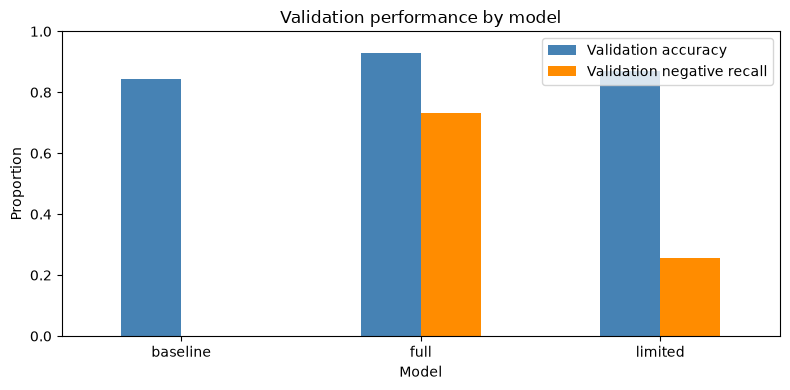

In [61]:
# Your code: assemble validation_comparison from existing results and plot the two validation metrics.

# Compare the three approaches on the same training and validation rows
validation_comparison = pd.DataFrame(
    {
        "Training accuracy": [
            baseline_training_accuracy, full_training_accuracy, limited_training_accuracy
        ],
        "Validation accuracy": [
            baseline_validation_accuracy, full_validation_accuracy, limited_validation_accuracy
        ],
        "Validation negative recall": [
            baseline_negative_recall, full_negative_recall, limited_negative_recall
        ],
        "Vocabulary size": [
            0,
            len(full_vectorizer.get_feature_names_out()),
            len(limited_vectorizer.get_feature_names_out()),
        ],
        "Fit time (s)": [np.nan, full_fit_seconds, limited_fit_seconds],
        "Validation prediction time (s)": [
            np.nan, full_predict_seconds, limited_predict_seconds
        ],
    },
    index=["baseline", "full", "limited"],
)
display(validation_comparison)

# Plot both validation metrics on the same scale
metrics = ["Validation accuracy", "Validation negative recall"]
ax = validation_comparison[metrics].plot.bar(
    figsize=(8, 4), rot=0, color=["steelblue", "darkorange"]
)
ax.set_title("Validation performance by model")
ax.set_xlabel("Model")
ax.set_ylabel("Proportion")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

In [62]:
required = ["limited_vectorizer", "limited_model", "limited_validation_predictions", "limited_validation_accuracy", "limited_training_accuracy", "limited_negative_recall", "validation_comparison"]
assert all(name in globals() for name in required), "Finish the 20-word experiment and decision table first."
assert set(limited_vectorizer.get_feature_names_out()) == set(significant_words), "Use exactly the supplied 20-word vocabulary."
expected_limited = limited_model.predict(limited_vectorizer.transform(validation_data["review_clean"]))
assert np.array_equal(limited_validation_predictions, expected_limited), "Keep limited predictions aligned with the same validation rows."
assert np.isclose(limited_validation_accuracy, accuracy_score(y_validation, expected_limited)), "Check limited-model validation accuracy."
assert np.isclose(limited_negative_recall, recall_score(y_validation, expected_limited, pos_label=-1)), "Check the negative-class recall."
assert len(validation_comparison) == 3, "Compare the baseline and both logistic models."
print("Checkpoint passed: both vocabularies were evaluated on the same validation reviews.")


Checkpoint passed: both vocabularies were evaluated on the same validation reviews.


**Decide before testing:** Compare both vocabularies using validation accuracy,
negative recall, vocabulary size, and the measured times. What did the smaller
vocabulary gain and lose? Choose one approach and justify the tradeoff.
If both accuracy and negative recall favour one model, say so.

Then assign **chosen_name** to "baseline", "full", or "limited" in the next cell.
Keep the standard prediction rule; threshold experiments are optional later.


_Your answer:_


In [65]:
# Your code: assign chosen_name after explaining your validation-based decision.
chosen_name = "full"

### Final assessment — a familiar refit, now including text preprocessing

**Your turn — construct the final workflow.** The regression primer supplied
the final refit; this time you implement it. A pipeline ensures that learning
a vocabulary and fitting a classifier happen together.

For a tiny syntax example,
make_pipeline(CountVectorizer(), LogisticRegression(solver="liblinear"))
creates a model whose input is text. It has the usual .fit and .predict methods.
clone(estimator) copies settings into an unfitted estimator.

1. If chosen_name is "full" or "limited", construct **final_model** with
   make_pipeline(clone(the_chosen_vectorizer), clone(the_chosen_classifier)).
   If it is "baseline", use make_pipeline(CountVectorizer(), clone(baseline)).
2. Fit that fresh pipeline on development_data["review_clean"] and its sentiment
   labels. This combines training and validation data **after** your choice.
3. Obtain **final_predictions** on test_data["review_clean"]. Evaluate test
   accuracy and negative recall.
4. Separately fit **final_baseline**, a fresh pipeline containing CountVectorizer
   and DummyClassifier(strategy="most_frequent"), on the same development data.
   Obtain **final_baseline_predictions** on test text.
5. Display **final_results**, comparing those two approaches on test accuracy
   and negative recall. Draw a labelled test confusion matrix for final_model.

Relearning the full vocabulary on development text is now appropriate.
The fixed 20-word vocabulary stays fixed if selected. Neither approach learns
from test text or test labels. Do not change your choice after seeing test scores.


,Test accuracy,Test negative recall
Selected model (full),0.931102,0.727604
Majority baseline,0.842954,0.000000


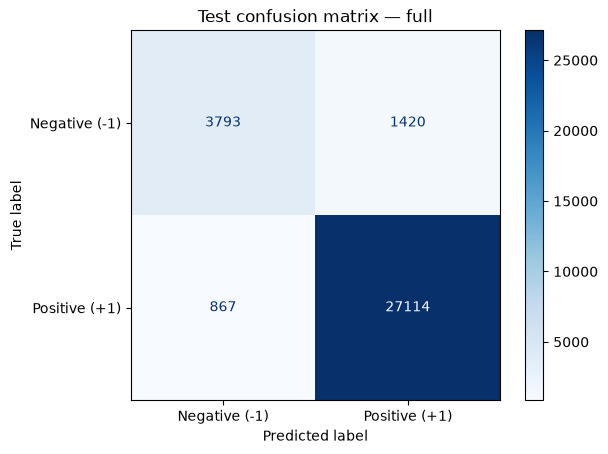

In [66]:
# Your code: create fresh pipelines, refit on development text, evaluate on test reviews, and plot the final confusion matrix.

# Create fresh pipelines for the selected model and the baseline
if chosen_name == "baseline":
    final_model = make_pipeline(CountVectorizer(), clone(baseline))
else:
    vectorizer, classifier = {
        "full": (full_vectorizer, full_model),
        "limited": (limited_vectorizer, limited_model),
    }[chosen_name]
    final_model = make_pipeline(clone(vectorizer), clone(classifier))

final_baseline = make_pipeline(
    CountVectorizer(),
    DummyClassifier(strategy="most_frequent"),
)

development_text = development_data["review_clean"]
y_development = development_data["sentiment"]
test_text = test_data["review_clean"]
y_test = test_data["sentiment"]

# Refit on development data and predict on the held-out test set
final_model.fit(development_text, y_development)
final_baseline.fit(development_text, y_development)

final_predictions = final_model.predict(test_text)
final_baseline_predictions = final_baseline.predict(test_text)

# Compare both models on the same test reviews
final_results = pd.DataFrame(
    {
        "Test accuracy": [
            accuracy_score(y_test, final_predictions),
            accuracy_score(y_test, final_baseline_predictions),
        ],
        "Test negative recall": [
            recall_score(y_test, final_predictions, pos_label=-1),
            recall_score(y_test, final_baseline_predictions, pos_label=-1),
        ],
    },
    index=[f"Selected model ({chosen_name})", "Majority baseline"],
)
display(final_results)

# Plot the selected model's test confusion matrix
test_confusion = confusion_matrix(y_test, final_predictions, labels=[-1, 1])
matrix_display = ConfusionMatrixDisplay(
    confusion_matrix=test_confusion,
    display_labels=["Negative (-1)", "Positive (+1)"],
)
matrix_display.plot(values_format="d", cmap="Blues")
matrix_display.ax_.set_title(f"Test confusion matrix — {chosen_name}")
plt.show()

In [67]:
required = ["chosen_name", "final_model", "final_predictions", "final_baseline", "final_baseline_predictions", "final_results"]
assert all(name in globals() for name in required), "Complete the choice, fresh refit, and final assessment."
assert chosen_name in {"baseline", "full", "limited"}, "Use a stated approach."
assert np.asarray(final_predictions).shape == (len(test_data),), "Obtain one label per test review."
assert np.array_equal(final_predictions, final_model.predict(test_data["review_clean"])), "Check the final text pipeline and test row order."
assert len(final_results) == 2, "Compare the chosen model and a development-fitted baseline."
print("Checkpoint passed: final predictions and the test comparison are ready.")


Checkpoint passed: final predictions and the test comparison are ready.


## Final reflection

Report the selected approach, its validation accuracy and negative recall before
refitting, and its final test accuracy and negative recall. Compare with the test
baseline. Why need the validation and test scores not match?

State two limits of this model or evaluation. Include one about the text/labels
and one about which future reviews this experiment can represent. Propose one
small extension and explain how you would compare it without repeatedly using
these test scores to choose the winner.


_Your answer:_

I chose logistic regression with the full vocabulary. Before refitting, it reached 93.01% validation accuracy and 73.05% negative recall. After refitting on the combined training and validation data, it reached 93.11% test accuracy and 72.76% negative recall.

The star ratings are an imperfect guide to sentiment. A four-star review can include a serious complaint and still be labelled positive. The split groups identical review texts, but the same products can appear across sets. These results are most relevant to similar reviews of baby products. Performance on new products or reviews posted later is still unknown.

I would try adding two-word phrases such as “not good” so the model can use some word order. I would train both versions on the original training set and compare accuracy and negative recall on the same validation set, keeping the test scores out of that decision.


### Submission checklist

- Complete all core code blocks, plots, the model choice, and written answers.
- Keep the supplied groups and fixed model settings; use every eligible review.
- Label probabilities, proportions, percentages, and percentage-point differences clearly.
- Support comparisons with validation evidence and report negative-review errors.
- Restart the kernel and run the completed core notebook in order.
- Submit the completed notebook with useful tables and plots retained.

Optional work is not required for a complete core submission.


## Optional extensions

### A. Change the decision threshold — validation experiment only

The binary classifier normally predicts +1 above a positive probability of 0.5
(an exact tie may be resolved by label order). A different threshold changes
decisions **without refitting** the coefficients.

**Your turn:** using full_p_positive and the same validation labels, write a
loop for thresholds **0.2, 0.5, and 0.8**. For each, predict +1 when
P(+1) >= threshold and −1 otherwise. Build **threshold_results** with accuracy,
negative recall, and **negative precision**.

Negative precision asks: of all reviews we flagged as negative, what share
actually had a negative label? Use precision_score(..., pos_label=-1,
zero_division=0); zero_division=0 records 0 if no negative predictions exist.
Construct a line plot of negative precision and recall against threshold.

Keep the completed core test result and its standard rule unchanged. This is
a validation exploration, not an invitation to tune using test errors.


In [ ]:
# Your code: loop over thresholds, construct threshold_results, and plot negative precision and recall.


**Explain:** Which direction of threshold change flags more reviews as negative?
What happens to negative recall and precision in your results? Which might a
complaint-screening team prefer if staff time is limited? Would any particular
threshold be universally best?


_Your answer:_


### B. Try short texts and expose a representation limit

**Your turn:** create at least four short reviews, including the exact pair
"not good" and "good not", one example containing love, and one containing
disappointed. Clean them with the same rule as training. Use the fitted
**full_vectorizer and full_model** to build a table of labels and positive
probabilities. Do not fit on your examples.

Check whether the count vectors for the first pair are identical. Interpret
the predictions cautiously: these artificial snippets are a demonstration,
not a representative accuracy test, and no labelled evaluation set is supplied.


In [ ]:
# Your code: create and clean short texts, predict without fitting, and compare the reordered pair's vectors.


**Explain:** What does the reordered pair demonstrate? What would you need
before treating success on your own short examples as evidence of useful
performance on other people's reviews?


_Your answer:_


## Optional reference links

- [CountVectorizer and its tokenisation settings](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.CountVectorizer.html)
- [LogisticRegression and probability output](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html)
- [DummyClassifier baselines](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html)
- [Confusion-matrix row and column conventions](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html)
- [Consistent preprocessing and data leakage](https://scikit-learn.org/stable/common_pitfalls.html)
